# Visualisation des données de `student_perf.csv`

## Import des librairies

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

On utilise `encoding="utf-8-sig"` pour retirer le BOM (*Byte Order Mark*) devant le nom des colonnes.

In [11]:
df_student = pd.read_csv("student_perf.csv", encoding="utf-8-sig")
df_student

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0
...,...,...,...,...,...,...
9995,1,49,Yes,4,2,23.0
9996,7,64,Yes,8,5,58.0
9997,6,83,Yes,8,5,74.0
9998,9,97,Yes,7,0,95.0


Le DataFrame contient 10000 lignes et 6 colonnes.

In [12]:
df_student.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0    Hours Studied                    10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


Chaque colonne contient 10 000 données non nulles : ce jeu de données ne contient donc pas de valeur manquante.

Nous remarquons qu'il y a n'y a que des colonnes à valeurs numériques sauf pour *Extracurricular Activities*, qui est une colonne à valeurs binaires que nous allons one-hot encode par la suite.

Nous remarquons également qu'il y a un espace en plus pour ` Hours Studied`. Enlevons-le.

In [13]:
df_student.columns = df_student.columns.str.strip()
print(df_student.columns.tolist())

['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']


L'espace en trop a bien été retiré.

array([[<Axes: title={'center': 'Hours Studied'}>,
        <Axes: title={'center': 'Previous Scores'}>],
       [<Axes: title={'center': 'Sleep Hours'}>,
        <Axes: title={'center': 'Sample Question Papers Practiced'}>],
       [<Axes: title={'center': 'Performance Index'}>, <Axes: >]],
      dtype=object)

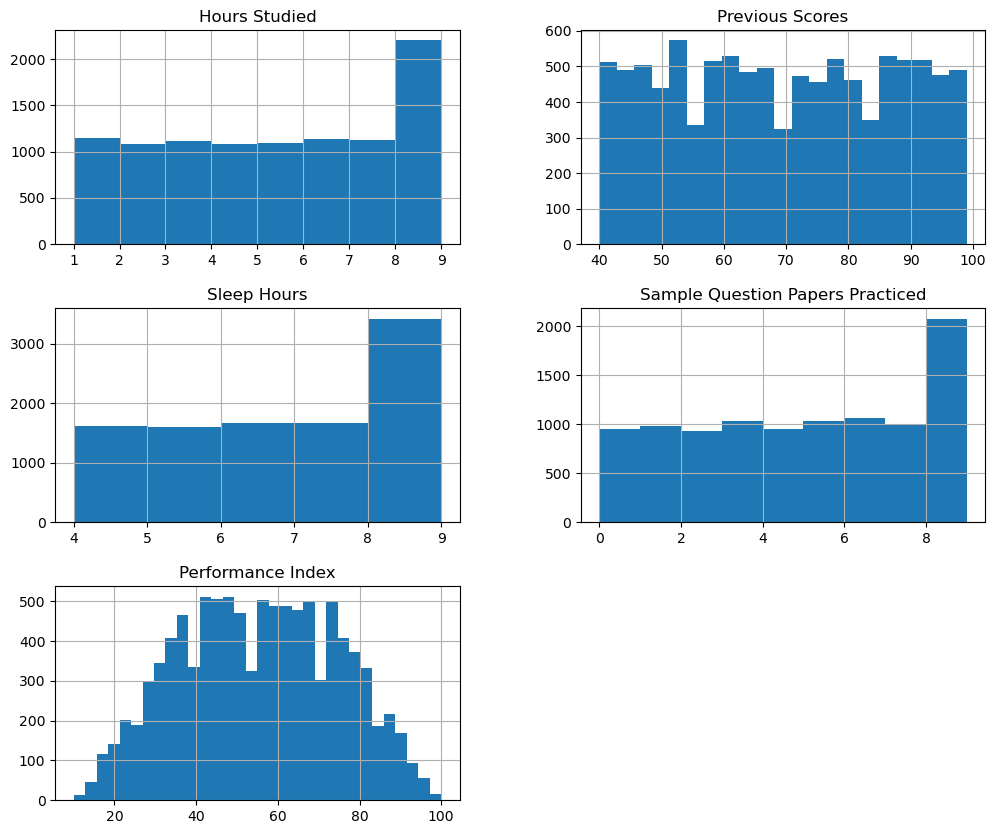

In [14]:
df_student.hist(bins='auto', figsize=(12, 10))

Le découpage automatique de matplotlib donne l'impression qu'il y a un déséquilibre. Construisons les histogrammes avec un découpage plus adapté.

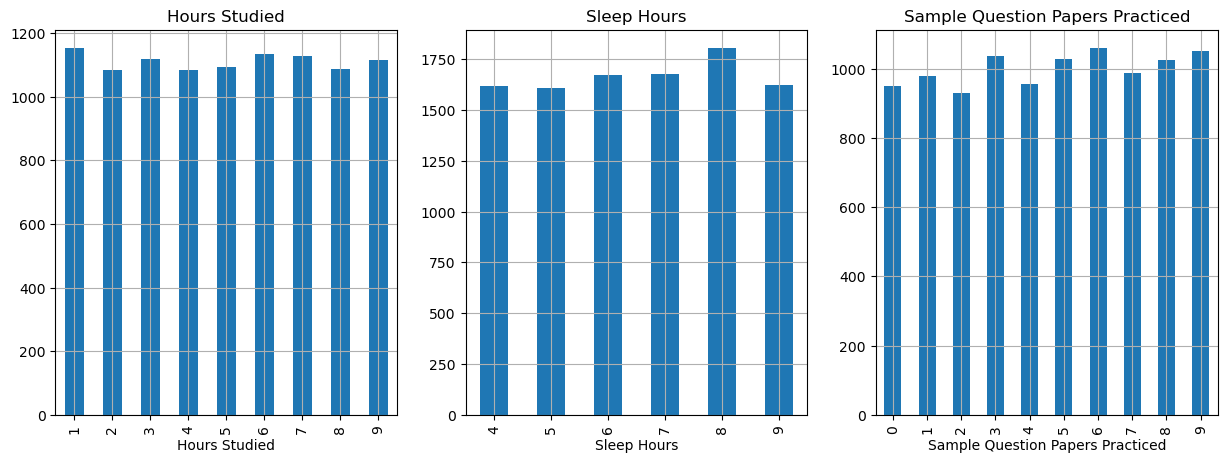

In [ ]:
cols_reg = ["Hours Studied", "Sleep Hours", "Sample Question Papers Practiced"] #reg pour régulier
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for axes, col in zip(axes, cols_reg):
    df_student[col].value_counts().sort_index().plot.bar(ax=axes, title=col, grid=True)

La ligne de code `df_student[c].value_counts().sort_index().plot.bar(ax=ax, title=c)` permet de :
* sélectionner une colonne de `cols_int` (`df_student[c]`)
* compter combien de fois chaque valeur apparaît (`value_counts`)
* trier la `Series` sélectionnées selon l'index et non pas selon son effectif
* dessiner un diagramme en barres : une barre par ligne avec l'index en abscisse et l'effectif en ordonnée

In [20]:
print(f"Minimum Previous Scores : {df_student['Previous Scores'].min()}")
print(f"Maximum Previous Scores : {df_student['Previous Scores'].max()}")
print(f"Minimum Performance Index : {df_student['Performance Index'].min()}")
print(f"Maximum Performance Index : {df_student['Performance Index'].max()}")

Minimum Previous Scores : 40
Maximum Previous Scores : 99
Minimum Performance Index : 10.0
Maximum Performance Index : 100.0


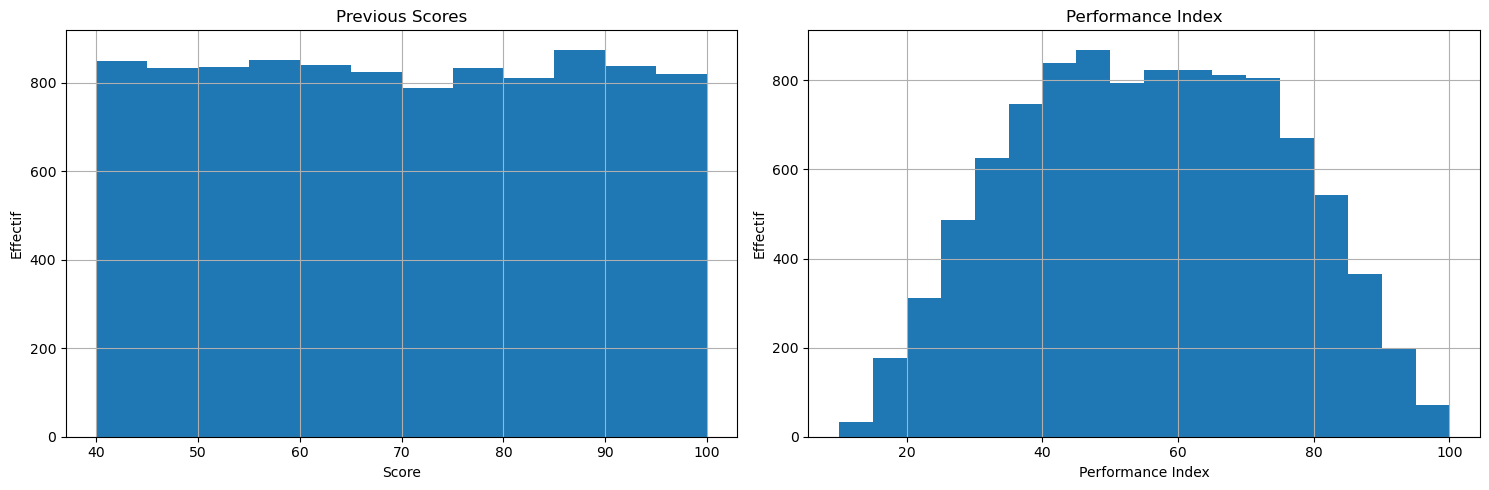

In [24]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

df_student["Previous Scores"].hist(bins=range(40, 101, 5), ax=axes[0])
axes[0].set_title("Previous Scores")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Effectif")

df_student["Performance Index"].hist(bins=range(10, 101, 5), ax=axes[1])
axes[1].set_title("Performance Index")
axes[1].set_xlabel("Performance Index")
axes[1].set_ylabel("Effectif")

plt.tight_layout()

In [16]:
df_student.columns

Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='object')

In [17]:
print(df_student['Extracurricular Activities'].value_counts())

Extracurricular Activities
No     5052
Yes    4948
Name: count, dtype: int64


Nous remarquons alors que toutes les colonnes sont équilibrées, à part la colonne cible `Performance Index`. En effet, cette colonne a une distribution en cloche. Nous pouvons alors nous attendre à des prédictions moins robustes en ce qui concerne les valeurs extrêmes.